# Model selection

From data analysis: the target is a futures price, and the futures curve already includes things like storage and the season. So my plan is

forecast = price the futures market expects × a small correction learned by a model

Everything in this notebook is done inside the training file (Sep 2003 to Aug 2020).

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src import config
from src.data import load_all
from src.evaluate import accuracy_table
from src.features import CANDIDATES, build_candidate_features, build_features, market_view
from src.model import forecast_all_horizons, futures_curve_forecast, make_model, no_change_forecast

data = load_all()
features = build_features(data)

## Features for the correction

I use three features, all known at the end of the month:

- `month_end_move`: change of the gas futures index (BCOMNG_INDX) during the month, on the last day. Because the target is a monthly average, a jump at the end of the month shows up in next month's average.
- `price_change_1m`: change of the monthly average price. Together with the first one it shows how much of the move is not in the average yet.
- `oil_change_3m`: oil price change over 3 months. Oil and gas react to the same changes in energy demand.

The model is ridge regression (linear, alpha = 10), one per horizon. It predicts the log ratio between the real price and the market's expectation, and the forecast is market view × exp(prediction).

### Validation split

Train on 2003-2012, forecast Jan 2013 - Aug 2020, measure MAPE. It's a time split because the model will always forecast the future from the past.

Two baselines that any model has to beat:
- no change: next price = this month's price
- futures curve only: the market's expectation without any correction

In [2]:
practice_dates = data.index[(data.index > config.PRACTICE_TRAIN_END) & (data.index <= config.TRAIN_END)]


def practice_forecast(data, features, make=make_model):
    forecasts, _ = forecast_all_horizons(data, features, config.PRACTICE_TRAIN_END, make)
    return forecasts


def practice_scores(contenders):
    # known_until: don't score outcomes after Aug 2020, those are in the test period
    return accuracy_table(data, contenders, practice_dates, known_until=config.TRAIN_END)


def gradient_boosting():
    return GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03,
                                     min_samples_leaf=15, subsample=0.8, loss="huber", random_state=0)


def random_forest():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0)


def lasso():
    return make_pipeline(StandardScaler(), Lasso(alpha=0.01))


def elastic_net():
    return make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5))

/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/min

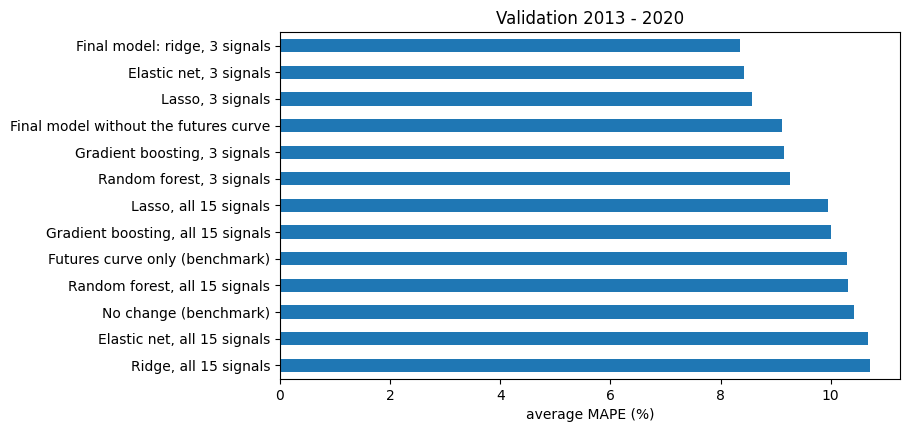

,1m ahead,2m ahead,3m ahead,average
No change (benchmark),7.53,10.43,13.30,10.42
Futures curve only (benchmark),7.46,10.49,12.94,10.30
"Final model: ridge, 3 signals",5.64,8.32,11.09,8.35
Final model without the futures curve,6.05,9.38,11.92,9.12
"Ridge, all 15 signals",6.39,11.27,14.51,10.72
"Gradient boosting, 3 signals",5.99,9.51,11.96,9.15
"Gradient boosting, all 15 signals",6.04,10.16,13.82,10.01
"Random forest, 3 signals",6.16,9.74,11.89,9.26
"Random forest, all 15 signals",6.38,10.03,14.54,10.32
"Lasso, 3 signals",5.91,8.66,11.13,8.57


In [3]:
all_features = features.join(build_candidate_features(data))   # 3 + 12 = 15 features

# same model but with a flat futures curve, to see how much the futures data helps
flat_curve = data.assign(fut_c2=data["fut_c1"], fut_c3=data["fut_c1"], fut_c4=data["fut_c1"])

practice = practice_scores({
    "No change (benchmark)": no_change_forecast(data),
    "Futures curve only (benchmark)": futures_curve_forecast(data),
    "Final model: ridge, 3 signals": practice_forecast(data, features),
    "Final model without the futures curve": practice_forecast(flat_curve, features),
    "Ridge, all 15 signals": practice_forecast(data, all_features),
    "Gradient boosting, 3 signals": practice_forecast(data, features, gradient_boosting),
    "Gradient boosting, all 15 signals": practice_forecast(data, all_features, gradient_boosting),
    "Random forest, 3 signals": practice_forecast(data, features, random_forest),
    "Random forest, all 15 signals": practice_forecast(data, all_features, random_forest),
    "Lasso, 3 signals": practice_forecast(data, features, lasso),
    "Lasso, all 15 signals": practice_forecast(data, all_features, lasso),
    "Elastic net, 3 signals": practice_forecast(data, features, elastic_net),
    "Elastic net, all 15 signals": practice_forecast(data, all_features, elastic_net),
})

practice["average"].sort_values(ascending=False).plot.barh(figsize=(8, 4.5))
plt.xlabel("average MAPE (%)")
plt.title("Validation 2013 - 2020")
plt.show()

practice.round(2)

The ridge model with 3 features is the best at every horizon, 8.35% on average vs 10.4% for no change.

Without the futures curve the same model gets 9.1%, so the external futures data really helps.

Lasso and elastic net (alpha 0.01) can drop features by themselves. With all 15 features lasso gets 9.96%, better than ridge with 15 (10.72%), but still worse than ridge with my 3 features (8.35%).

The more complex models are worse. Gradient boosting and random forest with the same 3 features get 9.2-9.3%, and with all 15 features they're about as bad as the baselines. There are only around 110 training months, which is probably not enough for flexible models.

### Ablation Study

Remove one feature at a time. `change_vs_final` > 0 means the model got worse without it.

In [4]:
contenders = {"Final model (3 signals)": practice_forecast(data, features)}
for name in features.columns:
    contenders[f"without {name}"] = practice_forecast(data, features.drop(columns=name))

drop_one = practice_scores(contenders)
drop_one["change_vs_final"] = drop_one["average"] - drop_one.loc["Final model (3 signals)", "average"]
drop_one.round(2)

,1m ahead,2m ahead,3m ahead,average,change_vs_final
Final model (3 signals),5.64,8.32,11.09,8.35,0.00
without month_end_move,7.02,9.31,11.53,9.29,0.94
without price_change_1m,6.16,8.58,11.24,8.66,0.31
without oil_change_3m,5.78,8.82,11.44,8.68,0.33


All three help, `month_end_move` the most (+0.94 without it).

## Other features I tried

I added each of these to the model one at a time. The official statistics are shifted by 2 months.

- storage_surplus: storage vs its 5-year average
- storage_surplus_change_3m: is the surplus growing or shrinking
- production_growth: production vs a year ago
- consumption_vs_normal: consumption vs the 5-year average for that month
- weather_demand: Boston temperature vs normal (cold winter / hot summer)
- rig_count_change_6m: drilling rigs, less drilling now means less gas later
- lng_export_share_change: LNG exports as a share of production
- europe_price_gap: European price vs US price
- dollar_change_1m: dollar index
- price_vs_12m_average: price vs its own 12-month average
- season: sine and cosine of the month

In [5]:
candidates = build_candidate_features(data)
contenders = {"Final model (3 signals)": practice_forecast(data, features)}
for name in CANDIDATES:
    cols = ["season_sin", "season_cos"] if name == "season" else [name]
    contenders[name] = practice_forecast(data, features.join(candidates[cols]))

tried = practice_scores(contenders)
tried["change_vs_final"] = tried["average"] - tried.loc["Final model (3 signals)", "average"]
tried[["average", "change_vs_final"]].round(2)

/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/asanali/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid

,average,change_vs_final
Final model (3 signals),8.35,0.00
storage_surplus,9.74,1.39
storage_surplus_change_3m,8.59,0.24
production_growth,8.55,0.20
consumption_vs_normal,8.48,0.13
weather_demand,8.64,0.29
rig_count_change_6m,8.48,0.13
lng_export_share_change,9.59,1.24
europe_price_gap,8.37,0.02
dollar_change_1m,8.33,-0.02


None of them helps much. Storage (+1.39) and LNG (+1.24) actually make it worse.

I don't think this means storage doesn't matter. The futures market already prices it in data analysis, so adding it again 2 months late is just noise for the model.

The dollar and the season improve it by less than 0.1. With 92 months that's within chance, so I didn't add them and kept 3 features.

## Decision

Final model: futures market view × ridge correction with 3 features, one model per horizon. It's the best on validation, simple, and the weights are easy to read.

Next I train it on the whole training file and forecast the 48 test months.